In [ ]:
# Standard imports and custom module loading
import sys
import os
from pathlib import Path
from typing import List, Tuple
# Ensure 'src' is in the path for modular imports
src_path = Path('../src').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Import custom modules from src
from square_geometry import get_square_lattice_subsets, gridGraph, get_node_mapping
from utils import save_something, load_something

print(f"Qiskit version: {qiskit.__version__}")
print("Environment loaded successfully. Modules imported from src/.")

Qiskit version: 2.6.1
Environment loaded successfully. Modules imported from src/.


In [ ]:
import networkx as nx
from qiskit.circuit.library import PhaseGate, XXPlusYYGate

def get_qiskit_subset_library(full_subsets):
    qiskit_subset_library = []
    for edge_list in full_subsets:
        current_subset_bonds = []
        processed_pairs = set()
        for u, v in edge_list:
            pair = tuple(sorted((u, v)))
            if pair in processed_pairs:
                continue
            processed_pairs.add(pair)
            current_subset_bonds.append((u, v))
        qiskit_subset_library.append(current_subset_bonds)
    return qiskit_subset_library

# --- CIRCUIT CONSTRUCTORS ---

def build_final_circuit(p_steps, params, subset_library, num_qubits, start_indices, barrier=False, include_nn=None, apply_X = None, apply_Y = None):
    qc = QuantumCircuit(num_qubits)
    qc.x(start_indices)
    qc.barrier()

    has_nn_params = 'v_nn_0' in params

    # --- SINGLE PLACE FOR ROUND TO ZERO FILTER ---
    round_to_zero = 1e-4
    def filter_val(val):
        return 0.0 if np.abs(val) < round_to_zero else val
    filter_val = np.vectorize(filter_val)
    # ---------------------------------------------

    nn_param_idx = []
    if has_nn_params:
        v_nn_rows = params['v_nn_0'].shape[0]
        
        if include_nn is not None and not isinstance(include_nn, bool):
            nn_schedule = [bool(x) for x in include_nn]
        elif v_nn_rows == p_steps:
            nn_schedule = [True] * p_steps
        elif include_nn is True:
            nn_schedule = [True] * p_steps
        else:
            nn_schedule = [True] * v_nn_rows + [False] * (p_steps - v_nn_rows)

        curr_active_row = 0
        for is_active in nn_schedule:
            if is_active and curr_active_row < v_nn_rows:
                nn_param_idx.append(curr_active_row)
                curr_active_row += 1
            else:
                nn_param_idx.append(-1)
    else:
        nn_param_idx = [-1] * p_steps

    for p in range(p_steps):
        p_idx = nn_param_idx[p]
        
        for s_idx, bond_list in enumerate(subset_library):
            h_real = filter_val(params[f'h_real_{s_idx}'][p])
            h_imag = filter_val(params[f'h_imag_{s_idx}'][p])
            
            step_has_nn = (p_idx != -1)
            if step_has_nn:
                v_nn = filter_val(params[f'v_nn_{s_idx}'][p_idx])
            
            for e_idx, (u, v) in enumerate(bond_list):
                jr = h_real[e_idx]
                ji = h_imag[e_idx]
                
                if jr != 0 or ji != 0:
                    j_val = jr + 1j*ji
                    mag = np.abs(j_val)
                    phi = np.angle(j_val)
                    qc.append(XXPlusYYGate(-2 * mag, phi), [u, v])
                
                if step_has_nn:
                    v_nn_val = v_nn[e_idx]
                    if v_nn_val != 0:
                        qc.cp(-v_nn_val, u, v)

        v_w = filter_val(params['v_pots'][p])
        for i in range(num_qubits):
            if v_w[i] != 0:
                qc.append(PhaseGate(-v_w[i]), [i])
                
        if barrier:
            qc.barrier()

    # --- MEASUREMENT BASIS ROTATIONS ---
    if apply_X or apply_Y:
        qc.barrier()

    if apply_X:
        for q in apply_X:
            qc.h(q)

    if apply_Y:
        for q in apply_Y:
            qc.sdg(q)  # S^\dagger gate
            qc.h(q)
        
    # Append final measurement layer required for execution pipelines
    qc.measure_all()
    return qc


In [3]:
import os
import joblib
from pathlib import Path
import numpy as np

# File and directory configuration
file_dict = {
    "2h":"KM_4x4_L_nn_010_2h_p3_50_20260711_012241",
    "0h_long":"KM_4x4_L_nn_0111_center_p4_46_20260717_032456",
    "0h_short":"KM_4x4_L_nn_011_center_p3_64_20260718_171556",
}

filename = file_dict["2h"]
base_data_dir = Path("../results_data")
run_dir = base_data_dir / filename
run_dir.mkdir(parents=True, exist_ok=True)

# 1. Load optimization data (.pkl) using the original function signature
# We pass the nested subfolder path to the 'directory' argument
opt_data = load_something(filename, directory=str(run_dir))
tgt_info = opt_data['tgt_info']
Ly, Lx = tgt_info['dims']
M = Ly * Lx

# 2. Setup geometries and mappings
nodes_sorted, mapping = get_node_mapping(Ly, Lx)
start_indices = [mapping[node] for node in opt_data['start_sites']]
q_library = get_qiskit_subset_library(get_square_lattice_subsets(Ly, Lx))
include_nn = tgt_info.get('include_nn')

print(f"Successfully loaded optimization file from: {run_dir / f'{filename}.pkl'}")
print(f"Number of circuit steps (p): {opt_data['p']}")

Successfully loaded optimization file from: ../results_data/KM_4x4_L_nn_010_2h_p3_50_20260711_012241/KM_4x4_L_nn_010_2h_p3_50_20260711_012241.pkl
Number of circuit steps (p): 3


In [4]:
# --- BACKEND CONFIGURATION ---
from qiskit_ibm_runtime.fake_provider import FakeMiami
# Toggle between local simulation (default) and real hardware execution
USE_FAKE_BACKEND = True
HAVE_ACCESS_TO_REAL = False
if not HAVE_ACCESS_TO_REAL:
    backend = AerSimulator.from_backend(FakeMiami(), method="statevector")
else:
    backend_name = 'ibm_miami'
    service = QiskitRuntimeService()
    real_backend = service.backend(backend_name)

    if USE_FAKE_BACKEND:
        backend = AerSimulator.from_backend(real_backend)
        print(f"Using Fake Backend (AerSimulator) based on: {real_backend.name}")
    else:
        backend = real_backend
        print(f"Using Real Hardware Backend: {backend.name}")
        if hasattr(backend, 'properties') and backend.properties():
            print(f"Actual Calibration Date: {backend.properties().last_update_date}")

In [5]:
# --- MEASUREMENT CONFIGURATION ---
# Choose measurement mode: "currents" (XX, YY, XY, YX) or "z_basis" (computational basis populations)
MEASUREMENT_MODE = "z_basis"  # Options: "currents", "z_basis"

# Select target edges/bonds for measurement
#target_edges= [((0,1), (3,1)), ((3,2), (0,2)), ((1,3), (1,0))] 
#target_edges= [((1,0), (1,1)),((1,1), (0,1)), ((3,1),(2,1)), ((2,1),(2,0))]
#target_edges= [((2,3), (2,2)), ((2,2), (3,2)), ((0,2),(1,2)), ((1,2),(1,3))]
target_edges= [((2,3), (2,2))]
target_bonds = [(mapping[edge[0]], mapping[edge[1]]) for edge in target_edges]

if MEASUREMENT_MODE == "currents":
    bases_to_run = ['XX', 'YY', 'XY', 'YX']
    print(f"Mode: Current measurements across {len(target_bonds)} bonds in bases: {bases_to_run}")
elif MEASUREMENT_MODE == "z_basis":
    bases_to_run = ['Z']  # Standard computational basis (no extra rotation gates)
    print("Mode: Z-basis measurements (computational basis)")
else:
    raise ValueError(f"Unknown MEASUREMENT_MODE: {MEASUREMENT_MODE}")

Mode: Z-basis measurements (computational basis)


In [6]:
from qiskit.visualization import plot_circuit_layout
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# 1. Build the uncompiled base circuit (no measurement rotations yet)
raw_circuit = build_final_circuit(
    opt_data['p'], 
    opt_data['final_params'], 
    q_library, 
    M, 
    start_indices, 
    include_nn=include_nn
)

# 2. Compile locally using modern Preset Pass Managers to find the initial hardware layout
scheduling_method = "alap" if not USE_FAKE_BACKEND else None

pm_initial = generate_preset_pass_manager(optimization_level=3, backend=backend, scheduling_method=scheduling_method)
transpiled_c_unrot = pm_initial.run(raw_circuit)

# Extract physical qubits used by mapping virtual bits
virtual_bits = transpiled_c_unrot.layout.initial_layout.get_virtual_bits()
qubit_mapping = {}
for virt, phys in virtual_bits.items():
    virt_str = str(virt)
    if 'register=(16, "q")' in virt_str:
        try:
            virt_idx = int(virt_str.split('index=')[1].replace('>', ''))
            qubit_mapping[virt_idx] = phys
        except (IndexError, ValueError):
            continue

physical_qubits_used = [qubit_mapping[i] for i in range(16)]

# 3. Define spatial symmetry transformations (8 unique grid configurations)
def transform_hardware_grid(physical_list, rotations=0, reflect=False):
    if len(physical_list) != 16:
        raise ValueError(f"Expected a list of exactly 16 qubits, got {len(physical_list)}")
    grid = [physical_list[i:i+4] for i in range(0, 16, 4)]
    if reflect:
        grid = [row[::-1] for row in grid]
    k = rotations % 4
    for _ in range(k):
        grid = [list(row) for row in zip(*grid[::-1])]
    return [qubit for row in grid for qubit in row]

all_layouts = {}
for reflect in [False, True]:
    for r in [0, 1, 2, 3]:
        name = f"Rot_{r*90}_Ref_{reflect}"
        all_layouts[name] = transform_hardware_grid(physical_qubits_used, rotations=r, reflect=reflect)

print(f"Extracted physical qubits and generated {len(all_layouts)} spatial layout variants.")

Extracted physical qubits and generated 8 spatial layout variants.


In [7]:
def generate_measurement_batch(
    opt_data,
    q_library,
    M,
    start_indices,
    include_nn,
    target_bonds: List[Tuple[int, int]],
    bases_to_run: List[str],       
    all_layouts: dict,             
    backend
):
    """
    Generates transpiled circuits for either bond-current measurements 
    or a single set of 8 spatial layout configurations for Z-basis measurements.
    """
    pm_cache = {}
    for layout_name, custom_layout in all_layouts.items():
        pm_cache[layout_name] = generate_preset_pass_manager(
            optimization_level=3, 
            backend=backend, 
            initial_layout=custom_layout,
            scheduling_method=scheduling_method
        )

    transpiled_batch = []
    pub_mapping = []

    # --- Z-BASIS BRANCH: Run 8 layouts ONCE without looping over bonds ---
    if bases_to_run == ['Z']:
        raw_circuit = build_final_circuit(
            opt_data['p'], 
            opt_data['final_params'], 
            q_library, 
            M, 
            start_indices, 
            include_nn=include_nn,
            apply_X=None,
            apply_Y=None
        )

        for layout_name, pm in pm_cache.items():
            tc_variant = pm.run(raw_circuit)
            tc_variant.metadata = {
                "basis": "Z",
                "layout_name": layout_name
            }
            transpiled_batch.append(tc_variant)
            pub_mapping.append({
                "basis": "Z",
                "layout_name": layout_name
            })

    # --- CURRENTS BRANCH: Loop over target bonds and 4 basis rotations ---
    else:
        for (bond_i, bond_j) in target_bonds:
            base_rotations = {
                "XX": ([bond_i, bond_j], []),
                "YY": ([], [bond_i, bond_j]),
                "XY": ([bond_i], [bond_j]),
                "YX": ([bond_j], [bond_i]),
            }

            for base_name in bases_to_run:
                apply_X, apply_Y = base_rotations[base_name]

                raw_circuit = build_final_circuit(
                    opt_data['p'], 
                    opt_data['final_params'], 
                    q_library, 
                    M, 
                    start_indices, 
                    include_nn=include_nn,
                    apply_X=apply_X,
                    apply_Y=apply_Y
                )

                for layout_name, pm in pm_cache.items():
                    tc_variant = pm.run(raw_circuit)
                    tc_variant.metadata = {
                        "bond": [int(bond_i), int(bond_j)],
                        "basis": base_name,
                        "layout_name": layout_name
                    }
                    transpiled_batch.append(tc_variant)
                    pub_mapping.append({
                        "bond": [int(bond_i), int(bond_j)],
                        "basis": base_name,
                        "layout_name": layout_name
                    })

    print(f"Generated a batch of {len(transpiled_batch)} circuits.")
    return transpiled_batch, pub_mapping


# Shot budget allocation
Nshots_per_config = 10000
num_rotations = len(all_layouts)
shots_per_circuit = Nshots_per_config // num_rotations

transpiled_batch, pub_mapping = generate_measurement_batch(
    opt_data, q_library, M, start_indices, include_nn,
    target_bonds, bases_to_run, all_layouts, backend
)

print(f"Total circuits in batch: {len(transpiled_batch)}")
print(f"Shots per circuit layout: {shots_per_circuit}")
print(f"Total shots: {len(transpiled_batch) * shots_per_circuit}")

Generated a batch of 8 circuits.
Total circuits in batch: 8
Shots per circuit layout: 1250
Total shots: 10000



Depth: 137
Two-qubit depth: 28
Gate count: 1299
Nonlocal gate count: 166
Gate breakdown: SX: 571, RZ: 539, CZ: 166, MEASURE: 16, X: 5, BARRIER: 2
    
Last Calibration Date: None


/tmp/ipykernel_704381/1105622826.py:11: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in qc_temp.data:


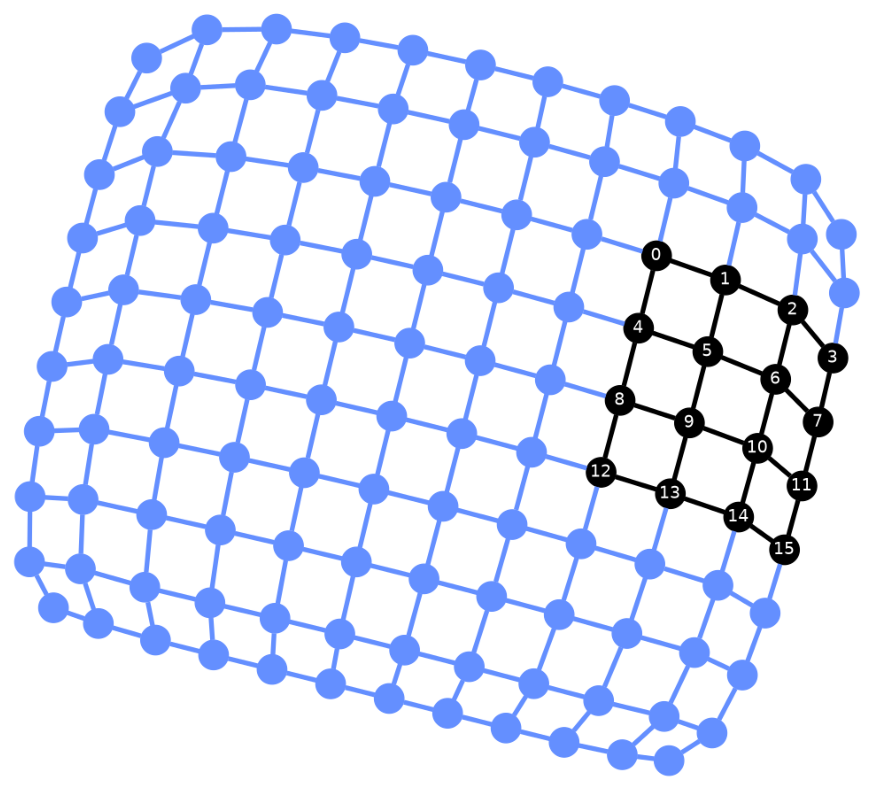

In [8]:
#See which qubits are chosen

def info_qc(qc_temp):
    # """Compute the sequential depth of two-qubit gates in a circuit."""
    depth2q = 0
    qubit_busy = {}

    # Map Qubit objects to their indices
    qubit_indices = {qubit: idx for idx, qubit in enumerate(qc_temp.qubits)}

    for instr, qargs, _ in qc_temp.data:
        if len(qargs) == 2:
            # Convert Qubit objects to indices
            idxs = [qubit_indices[q] for q in qargs]
            # Find the earliest time both qubits are free
            t = max(qubit_busy.get(i, 0) for i in idxs)
            # Set them as busy for the next time step
            for i in idxs:
                qubit_busy[i] = t + 1
            depth2q = max(depth2q, t + 1)
            
    print(f"""
Depth: {qc_temp.depth()}
Two-qubit depth: {depth2q}
Gate count: {len(qc_temp)}
Nonlocal gate count: {qc_temp.num_nonlocal_gates()}
Gate breakdown: {", ".join([f"{k.upper()}: {v}" for k, v in qc_temp.count_ops().items()])}
    """)

info_qc(transpiled_batch[0])
# Grab the true calendar timestamp of the last hardware calibration sweep
print("Last Calibration Date:", backend.properties().last_update_date)

plot_circuit_layout(transpiled_batch[0], backend)

In [ ]:
import json
import joblib
from qiskit_ibm_runtime import SamplerV2

# --- EXECUTION CONFIGURATION ---
job_name = f"run_{MEASUREMENT_MODE}"
pubs = [(circuit, None, shots_per_circuit) for circuit in transpiled_batch]

if USE_FAKE_BACKEND:
    # --- OPTION A: FAKE BACKEND (LOCAL SIMULATION) ---
    print(f"Running simulation locally using {backend.name}...")
    
    # 1. Initialize SamplerV2 pointing to local Aer backend
    sampler = SamplerV2(mode=backend)

    # 2. Format batch of circuits into V2 PUBs: (circuit, parameter_values, shots)
    pubs = [(circuit, None, shots_per_circuit) for circuit in transpiled_batch]

    # 3. Run and get a PrimitiveResult object
    job = sampler.run(pubs)
    result = job.result()  # This returns a proper PrimitiveResult

    # 4. Save locally
    results_path = run_dir / f"job_result_{job_name}.pkl"
    joblib.dump(result, results_path)
    
    print(f"Simulation complete! Results saved to: {results_path}")

Running simulation locally using aer_simulator_from(fake_miami)...


/tmp/ipykernel_704381/4232187340.py:14: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Simulation complete! Results saved to: ../results_data/KM_4x4_L_nn_010_2h_p3_50_20260711_012241/job_result_run_z_basis.pkl


In [ ]:
##### real hardware ####

In [ ]:
# --- EXECUTION CONFIGURATION ---
job_name = f"run_{MEASUREMENT_MODE}"
pubs = [(circuit, None, shots_per_circuit) for circuit in transpiled_batch]

if not USE_FAKE_BACKEND:
    # --- OPTION B: REAL BACKEND - STEP 1: SUBMISSION ---
    delay = 0.004
    sampler = Sampler(backend)
    
    # Apply hardware execution and dynamical decoupling options
    sampler.options.execution.rep_delay = delay
    sampler.options.execution.init_qubits = True
    sampler.options.twirling.enable_gates = False
    sampler.options.twirling.enable_measure = False
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XpXm"
    
    print(f"Submitting {len(transpiled_batch)} circuits to real backend: {backend.name}...")
    #job = sampler.run(pubs) #uncomment to run <==========================================================
    job_id = job.job_id()
    print(f"Job successfully submitted! Job ID: {job_id}")
    
    # Package metadata record mapping
    pub_mapping = [{
        "bond": tc.metadata.get("bond"),
        "basis": tc.metadata.get("basis"),
        "layout_name": tc.metadata.get("layout_name")
    } for tc in transpiled_batch]
    
    record_data = {
        "job_id": job_id,
        "backend_name": backend.name,
        "filename": filename,
        "measurement_mode": MEASUREMENT_MODE,
        "bases_to_run": bases_to_run,
        "pub_mapping": pub_mapping
    }
    
    record_path = run_dir / f"job_record_{job_name}.json"
    with open(record_path, "w") as f:
        json.dump(record_data, f, indent=4)
        
    print(f"Job record metadata saved to: {record_path}")
    print("When the hardware job finishes, run the next cell to collect and save results.")

In [ ]:
# --- REAL BACKEND - STEP 2: RETRIEVE COMPLETED JOB ---
# Only run this cell after the real hardware job has finished processing on IBM Quantum.

if USE_FAKE_BACKEND:
    print("Skipping: USE_FAKE_BACKEND is set to True. No remote job retrieval needed.")
else:
    job_name = f"run_{MEASUREMENT_MODE}"
    record_path = run_dir / f"job_record_{job_name}.json"
    
    with open(record_path, "r") as f:
        record_data = json.load(f)
        
    # Re-initialize service if needed (or use existing active service session)
    service = QiskitRuntimeService()
    
    print(f"Fetching job ID: {record_data['job_id']}")
    job = service.job(record_data["job_id"])
    
    status = job.status()
    print(f"Current Job Status: {status}")
    
    if status == "DONE":
        job_result = job.result()
        results_path = run_dir / f"job_result_{job_name}.pkl"
        joblib.dump(job_result, results_path)
        print(f"Results successfully downloaded and saved to: {results_path}")
    else:
        print(f"Job is not finished yet. Current status is '{status}'. Please check back later.")

In [ ]:
###########################